<a href="https://colab.research.google.com/github/isukanimalasuriya/J26-IT-313/blob/feature%2Ffinance/processing/notebook-finance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install xgboost scikit-learn pandas numpy matplotlib seaborn joblib

import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import xgboost as xgb
from xgboost import XGBRegressor
import joblib
from google.colab import files

sns.set_theme(style="whitegrid")
print("✅ Libraries installed and ready!")


✅ Libraries installed and ready!


In [3]:
print("Upload your 'coconut_finance_dataset.csv' from your local computer:")
uploaded = files.upload()

df = pd.read_csv("coconut_finance_dataset.csv")
print(f"✅ Dataset Loaded Successfully! Total Records: {len(df)}")
df.head(5)


Upload your 'coconut_finance_dataset.csv' from your local computer:


Saving coconut_finance_dataset.csv to coconut_finance_dataset (1).csv
✅ Dataset Loaded Successfully! Total Records: 1500


,district,land_size_acres,tree_count,tree_age_years,monthly_rainfall_mm,avg_temperature_c,drought_severity_index,fertilizer_applied_kg_per_tree,fertilizer_cost_lkr,labor_wage_rate_lkr,labor_cost_lkr,harvesting_cost_lkr,total_cultivation_cost_lkr,nuts_per_tree_pick,expected_yield_nuts,farm_gate_price_per_nut_lkr,total_revenue_lkr,net_profit_lkr,profit_margin_pct,risk_level
0,Puttalam,1.0,64,55,109.6,33.6,0.35,3.48,5939.29,2500,6093.19,5130.28,18219.85,7.8,499,117.26,58512.74,40292.89,68.86,Medium
1,Puttalam,2.0,138,45,72.6,35.0,0.42,2.40,10321.63,3000,13865.75,12932.86,40097.12,7.9,1090,114.85,125186.50,85089.38,67.97,Medium
2,Hambantota,4.0,264,42,32.0,34.2,0.51,2.20,17235.20,3500,52792.65,20024.15,96494.08,9.1,2402,123.33,296238.66,199744.58,67.43,Medium
3,Gampaha,20.0,1320,22,219.4,27.4,0.07,4.09,152100.43,3000,145140.84,96372.32,439351.20,15.0,19800,109.36,2165328.00,1725976.80,79.71,Low
4,Gampaha,1.5,82,48,283.4,28.1,0.05,3.92,8661.21,2500,13537.84,6316.87,30340.12,11.6,951,134.72,128118.72,97778.60,76.32,Low


In [4]:
# Features (Inputs) & Target (Output)
categorical_features = ["district"]
numerical_features = [
    "land_size_acres",
    "tree_count",
    "tree_age_years",
    "monthly_rainfall_mm",
    "avg_temperature_c",
    "drought_severity_index",
    "fertilizer_applied_kg_per_tree",
    "labor_wage_rate_lkr",
    "farm_gate_price_per_nut_lkr"
]

target_col = "net_profit_lkr"

X = df[categorical_features + numerical_features]
y = df[target_col]

# Split: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Preprocessor: One-Hot Encode categorical district, Scale numerical inputs
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
print(f"✅ Preprocessing complete! Feature dimensions: {X_train_prep.shape[1]}")


✅ Preprocessing complete! Feature dimensions: 15


In [5]:
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Random Forest (Baseline)": RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42),
    "XGBoost Regressor (Proposed)": XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42
    )
}

results = []
for name, model in models.items():
    model.fit(X_train_prep, y_train)
    y_pred = model.predict(X_test_prep)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        "Model": name,
        "R2 Score": round(r2, 4),
        "MAE (LKR)": round(mae, 2),
        "RMSE (LKR)": round(rmse, 2),
        "MAPE (%)": round(mape, 2)
    })

results_df = pd.DataFrame(results)
print("\n" + "="*65)
print("     📊 MODEL EVALUATION RESULTS FOR PPT1 SLIDES")
print("="*65)
display(results_df)

best_xgb = models["XGBoost Regressor (Proposed)"]
y_pred_xgb = best_xgb.predict(X_test_prep)



     📊 MODEL EVALUATION RESULTS FOR PPT1 SLIDES


,Model,R2 Score,MAE (LKR),RMSE (LKR),MAPE (%)
0,Linear Regression (Baseline),0.8732,72564.67,107691.62,39.14
1,Random Forest (Baseline),0.9087,57610.82,91370.85,25.35
2,XGBoost Regressor (Proposed),0.9277,50337.59,81309.94,19.93


/tmp/ipykernel_2223/1844980764.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[0], palette="viridis")


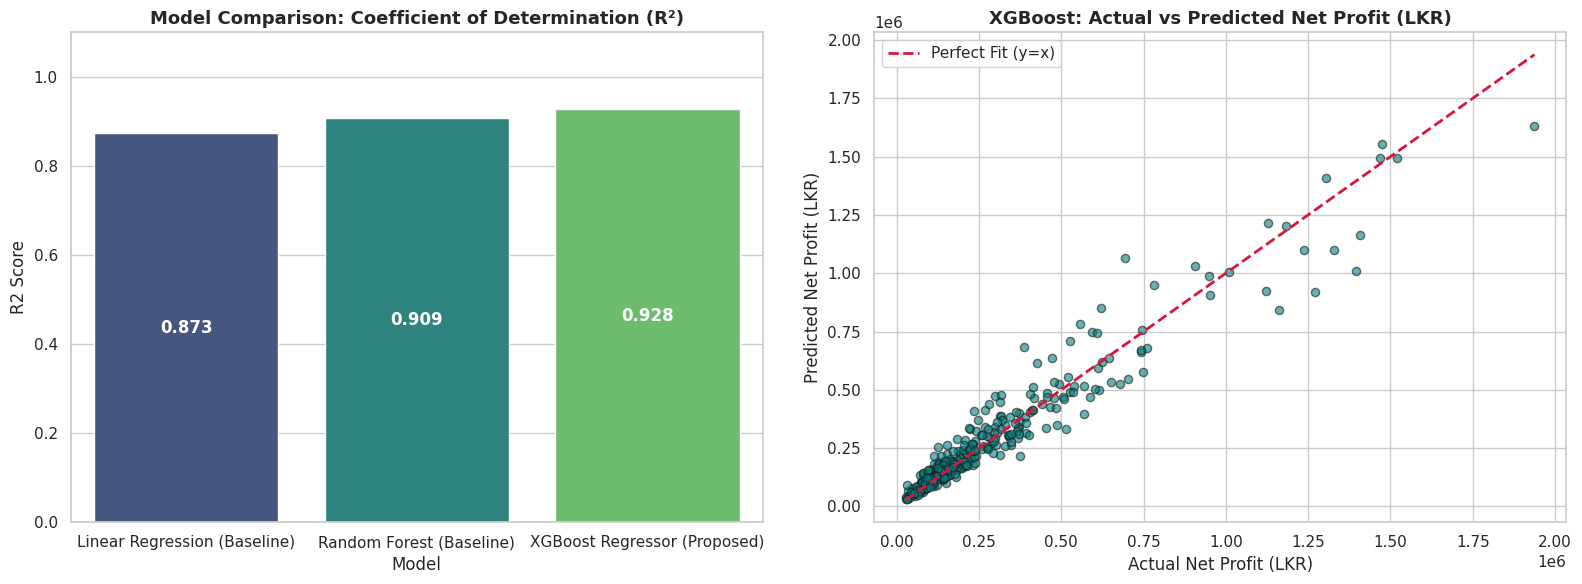

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Model Comparison (R2)
sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[0], palette="viridis")
axes[0].set_title("Model Comparison: Coefficient of Determination (R²)", fontsize=13, fontweight="bold")
axes[0].set_ylim(0, 1.1)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2.),
                     ha='center', va='center', fontsize=12, color='white', fontweight='bold')

# Plot 2: Actual vs Predicted Scatter
axes[1].scatter(y_test, y_pred_xgb, alpha=0.6, color="teal", edgecolors="k", s=35)
min_v = min(y_test.min(), y_pred_xgb.min())
max_v = max(y_test.max(), y_pred_xgb.max())
axes[1].plot([min_v, max_v], [min_v, max_v], color="crimson", linestyle="--", linewidth=2, label="Perfect Fit (y=x)")
axes[1].set_title("XGBoost: Actual vs Predicted Net Profit (LKR)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Actual Net Profit (LKR)")
axes[1].set_ylabel("Predicted Net Profit (LKR)")
axes[1].legend()

plt.tight_layout()
plt.savefig("model_comparison_and_fit.png", dpi=300)
plt.show()


/tmp/ipykernel_2223/410743092.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x="Importance", y="Feature", palette="mako")


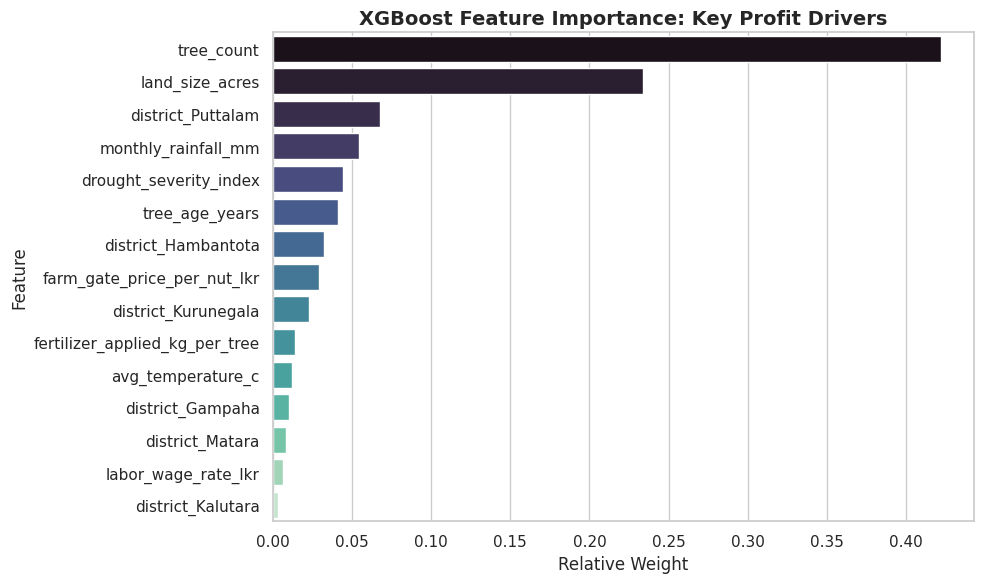

In [7]:
cat_encoded_cols = list(preprocessor.named_transformers_["cat"].get_feature_names_out(categorical_features))
all_feature_names = numerical_features + cat_encoded_cols

importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": best_xgb.feature_importances_
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature", palette="mako")
plt.title("XGBoost Feature Importance: Key Profit Drivers", fontsize=14, fontweight="bold")
plt.xlabel("Relative Weight")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()



     🎲 MONTE CARLO SIMULATION RESULTS (1,000 SCENARIOS)
Farm: Kurunegala, 5.0 Acres, 320 Trees
Expected Median Profit (P50) : LKR 382,970.09
Worst-Case Outcome (5% VaR)   : LKR 277,640.87
Best-Case Outcome (95th Pct)  : LKR 472,479.71
Probability of Loss           : 0.0%


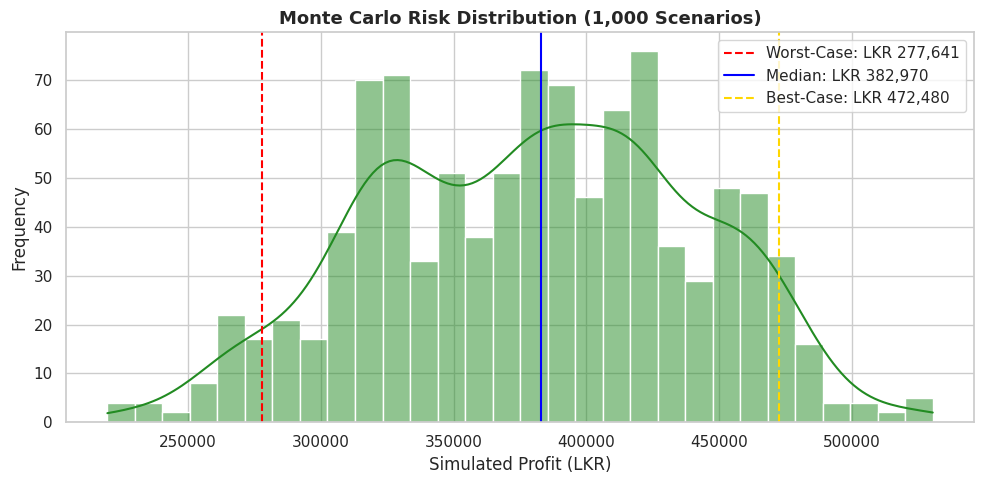

In [8]:
def run_monte_carlo(base_input: dict, prep, model, iterations: int = 1000):
    np.random.seed(42)
    simulated_profits = []
    base_price = base_input["farm_gate_price_per_nut_lkr"]
    base_rf = base_input["monthly_rainfall_mm"]
    base_wage = base_input["labor_wage_rate_lkr"]

    for _ in range(iterations):
        perturbed = base_input.copy()
        # Market shock (+/- 12%)
        perturbed["farm_gate_price_per_nut_lkr"] = max(70.0, np.random.normal(base_price, base_price * 0.12))
        # Weather / Drought shock (+/- 20%)
        rf_sim = max(20.0, np.random.normal(base_rf, base_rf * 0.20))
        perturbed["monthly_rainfall_mm"] = rf_sim
        perturbed["drought_severity_index"] = max(0.0, min(1.0, (75.0 - rf_sim)/75.0 if rf_sim < 75 else 0.10))
        # Labor drift (+/- 8%)
        perturbed["labor_wage_rate_lkr"] = np.random.normal(base_wage, base_wage * 0.08)

        df_single = pd.DataFrame([perturbed])[categorical_features + numerical_features]
        pred = float(model.predict(prep.transform(df_single))[0])
        simulated_profits.append(pred)

    sim_arr = np.array(simulated_profits)
    return {
        "p5_worst_case": np.percentile(sim_arr, 5),
        "p50_median": np.percentile(sim_arr, 50),
        "p95_best_case": np.percentile(sim_arr, 95),
        "loss_probability": np.mean(sim_arr < 0) * 100,
        "distribution": sim_arr
    }

# Test sample farm
sample_farm = {
    "district": "Kurunegala",
    "land_size_acres": 5.0,
    "tree_count": 320,
    "tree_age_years": 25,
    "monthly_rainfall_mm": 130.0,
    "avg_temperature_c": 29.5,
    "drought_severity_index": 0.12,
    "fertilizer_applied_kg_per_tree": 3.5,
    "labor_wage_rate_lkr": 3000,
    "farm_gate_price_per_nut_lkr": 118.0
}

sim = run_monte_carlo(sample_farm, preprocessor, best_xgb)

print("\n" + "="*65)
print("     🎲 MONTE CARLO SIMULATION RESULTS (1,000 SCENARIOS)")
print("="*65)
print(f"Farm: {sample_farm['district']}, {sample_farm['land_size_acres']} Acres, {sample_farm['tree_count']} Trees")
print(f"Expected Median Profit (P50) : LKR {sim['p50_median']:,.2f}")
print(f"Worst-Case Outcome (5% VaR)   : LKR {sim['p5_worst_case']:,.2f}")
print(f"Best-Case Outcome (95th Pct)  : LKR {sim['p95_best_case']:,.2f}")
print(f"Probability of Loss           : {sim['loss_probability']:.1f}%")

plt.figure(figsize=(10, 5))
sns.histplot(sim["distribution"], kde=True, color="forestgreen", bins=30)
plt.axvline(sim['p5_worst_case'], color='red', linestyle='--', label=f"Worst-Case: LKR {sim['p5_worst_case']:,.0f}")
plt.axvline(sim['p50_median'], color='blue', linestyle='-', label=f"Median: LKR {sim['p50_median']:,.0f}")
plt.axvline(sim['p95_best_case'], color='gold', linestyle='--', label=f"Best-Case: LKR {sim['p95_best_case']:,.0f}")
plt.title("Monte Carlo Risk Distribution (1,000 Scenarios)", fontsize=13, fontweight="bold")
plt.xlabel("Simulated Profit (LKR)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.savefig("monte_carlo_distribution.png", dpi=300)
plt.show()


In [9]:
# Save preprocessor
joblib.dump(preprocessor, "finance_preprocessor.joblib")

# Save XGBoost Model in JSON format
best_xgb.save_model("finance_model.json")

# Download directly to your local computer
print("Downloading artifacts...")
files.download("finance_model.json")
files.download("finance_preprocessor.joblib")
files.download("model_comparison_and_fit.png")
files.download("feature_importance.png")
files.download("monte_carlo_distribution.png")
print("✅ Done! Copy 'finance_model.json' and 'finance_preprocessor.joblib' to backend/trained_models/")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Done! Copy 'finance_model.json' and 'finance_preprocessor.joblib' to backend/trained_models/


In [10]:
# 1. Preprocessor (Scikit-Learn pipeline)
joblib.dump(preprocessor, "finance_preprocessor.joblib")

# 2. XGBoost Model as .joblib
joblib.dump(best_xgb, "finance_model.joblib")

# 3. XGBoost Model as .json (official XGBoost format)
best_xgb.save_model("finance_model.json")

# Download all 3 files
files.download("finance_preprocessor.joblib")
files.download("finance_model.joblib")
files.download("finance_model.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>